# 02 — Naive Bayes Classification & Calibration

## 1. Imports and Configuration


In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, brier_score_loss, confusion_matrix,
    ConfusionMatrixDisplay
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Preprocessing Setup


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Binary target
y = (df['Loan_Default'] == 'Yes').astype(int)

# Exclude leakage and identifiers
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

# Preprocessing: Note GaussianNB works on continuous scaled features
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')


## 3. Empirical Priors & Likelihoods


In [3]:
# Compute empirical frequencies on training set
n_total = len(df)
n_defaults = (df['Loan_Default'] == 'Yes').sum()
prior_yes = n_defaults / n_total
prior_no = 1.0 - prior_yes

# Likelihoods for Employment_Type == 'Unemployed'
unemployed_def = ((df['Employment_Type'] == 'Unemployed') & (df['Loan_Default'] == 'Yes')).sum()
unemployed_non = ((df['Employment_Type'] == 'Unemployed') & (df['Loan_Default'] == 'No')).sum()

lik_unemployed_given_yes = unemployed_def / n_defaults
lik_unemployed_given_no = unemployed_non / (n_total - n_defaults)

print('=== Empirical Priors and Likelihoods ===')
print(f'P(Default = Yes) [Prior]:                     {prior_yes:.4f} ({prior_yes*100:.2f}%)')
print(f'P(Default = No)  [Prior]:                     {prior_no:.4f} ({prior_no*100:.2f}%)')
print(f'P(Employment = Unemployed | Default = Yes):   {lik_unemployed_given_yes:.4f} ({lik_unemployed_given_yes*100:.2f}%)')
print(f'P(Employment = Unemployed | Default = No):    {lik_unemployed_given_no:.4f} ({lik_unemployed_given_no*100:.2f}%)')
print(f'Likelihood Ratio (Yes / No):                  {lik_unemployed_given_yes / lik_unemployed_given_no:.2f}x')

=== Empirical Priors and Likelihoods ===
P(Default = Yes) [Prior]:                     0.1978 (19.78%)
P(Default = No)  [Prior]:                     0.8022 (80.22%)
P(Employment = Unemployed | Default = Yes):   0.1512 (15.12%)
P(Employment = Unemployed | Default = No):    0.0410 (4.10%)
Likelihood Ratio (Yes / No):                  3.69x


## 4. Handling Rare Borrower Profiles with Laplace Smoothing

In [4]:
# Demonstrate how Laplace smoothing handles rare categories (zero historical defaults)
alpha = 1   # smoothing parameter
num_classes = 6
sample_size = 200

# Probability calculation with Laplace smoothing
smoothed_prob = (0 + alpha) / (sample_size + alpha * num_classes)
print(f"Laplace Smoothed Probability for Unseen Category: {smoothed_prob:.4f} ({smoothed_prob * 100:.2f}%)")

# Joint evidence combination for a sample applicant profile
p_default = 0.20
p_non_default = 0.80
lik_unemp_default = 0.12
lik_prev_default = 0.25
lik_unemp_non_default = 0.05
lik_prev_non_default = 0.04

score_default = lik_unemp_default * lik_prev_default * p_default
score_non_default = lik_unemp_non_default * lik_prev_non_default * p_non_default
posterior_default = score_default / (score_default + score_non_default)

print(f"Combined Default Risk Score:     {score_default:.6f}")
print(f"Combined Non-Default Risk Score: {score_non_default:.6f}")
print(f"Posterior Probability of Default: {posterior_default * 100:.2f}%")

Laplace Smoothed Probability for Unseen Category: 0.0049 (0.49%)
Combined Default Risk Score:     0.006000
Combined Non-Default Risk Score: 0.001600
Posterior Probability of Default: 78.95%


**Takeaway:** When an applicant has a rare combination of attributes that never defaulted in the training data, raw frequency would assign zero probability, completely overriding all other evidence. Laplace smoothing adds a small adjustment to ensure every attribute contributes reasonably to the overall risk assessment.

## 5. Fitting Gaussian Naive Bayes vs. Logistic Regression


In [5]:
# Gaussian Naive Bayes Pipeline
gnb = GaussianNB()
gnb_pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf', gnb)
])

gnb_pipeline.fit(X_train, y_train)

# Predictions
y_test_pred_gnb = gnb_pipeline.predict(X_test)
y_test_prob_gnb = gnb_pipeline.predict_proba(X_test)[:, 1]

# Also fit Logistic Regression for direct benchmark
lr_pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
lr_pipeline.fit(X_train, y_train)
y_test_pred_lr = lr_pipeline.predict(X_test)
y_test_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]

# Benchmark Table
nb_comp_df = pd.DataFrame([
    {
        'Model': 'Gaussian Naive Bayes',
        'Accuracy': accuracy_score(y_test, y_test_pred_gnb),
        'Precision': precision_score(y_test, y_test_pred_gnb),
        'Recall': recall_score(y_test, y_test_pred_gnb),
        'F1_Score': f1_score(y_test, y_test_pred_gnb),
        'ROC_AUC': roc_auc_score(y_test, y_test_prob_gnb),
        'Brier_Score': brier_score_loss(y_test, y_test_prob_gnb)
    },
    {
        'Model': 'Logistic Regression Baseline',
        'Accuracy': accuracy_score(y_test, y_test_pred_lr),
        'Precision': precision_score(y_test, y_test_pred_lr),
        'Recall': recall_score(y_test, y_test_pred_lr),
        'F1_Score': f1_score(y_test, y_test_pred_lr),
        'ROC_AUC': roc_auc_score(y_test, y_test_prob_lr),
        'Brier_Score': brier_score_loss(y_test, y_test_prob_lr)
    }
])

nb_comp_df.to_csv('../../outputs/tables/naive_bayes_vs_logistic_comparison.csv', index=False)
print('=== Gaussian Naive Bayes vs. Logistic Regression ===')
display(nb_comp_df)

=== Gaussian Naive Bayes vs. Logistic Regression ===


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Brier_Score
0,Gaussian Naive Bayes,0.8015,0.499072,0.679293,0.575401,0.840988,0.173484
1,Logistic Regression Baseline,0.8650,0.720280,0.520202,0.604106,0.890460,0.096449


## 6. Probability Calibration & Reliability Diagram


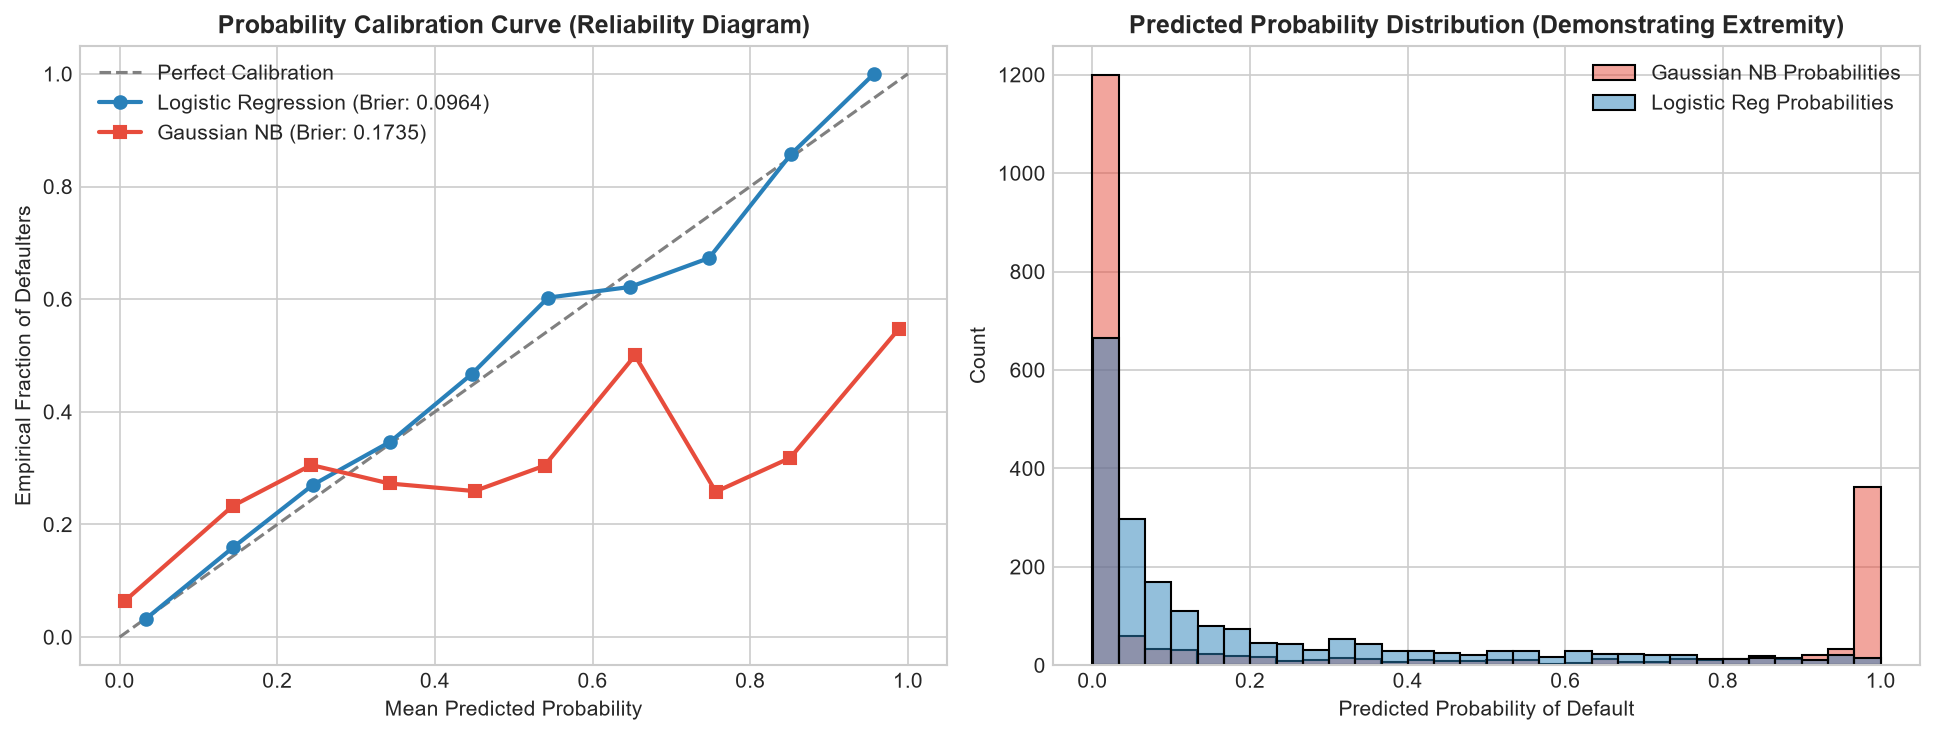

In [6]:
# Compute Calibration Curves
prob_true_gnb, prob_pred_gnb = calibration_curve(y_test, y_test_prob_gnb, n_bins=10)
prob_true_lr, prob_pred_lr = calibration_curve(y_test, y_test_prob_lr, n_bins=10)

brier_gnb = brier_score_loss(y_test, y_test_prob_gnb)
brier_lr = brier_score_loss(y_test, y_test_prob_lr)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Calibration Curve (Reliability Diagram)
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
axes[0].plot(prob_pred_lr, prob_true_lr, marker='o', color='#2980b9', lw=2, label=f'Logistic Regression (Brier: {brier_lr:.4f})')
axes[0].plot(prob_pred_gnb, prob_true_gnb, marker='s', color='#e74c3c', lw=2, label=f'Gaussian NB (Brier: {brier_gnb:.4f})')
axes[0].set_title('Probability Calibration Curve (Reliability Diagram)', weight='bold')
axes[0].set_xlabel('Mean Predicted Probability')
axes[0].set_ylabel('Empirical Fraction of Defaulters')
axes[0].legend()

# Probability Distribution Histograms
sns.histplot(y_test_prob_gnb, bins=30, ax=axes[1], color='#e74c3c', alpha=0.5, label='Gaussian NB Probabilities')
sns.histplot(y_test_prob_lr, bins=30, ax=axes[1], color='#2980b9', alpha=0.5, label='Logistic Reg Probabilities')
axes[1].set_title('Predicted Probability Distribution (Demonstrating Extremity)', weight='bold')
axes[1].set_xlabel('Predicted Probability of Default')
axes[1].legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_nb_calibration.png', dpi=150)
plt.show()

**Takeaway:** Naive Bayes produces pushed-to-the-extremes probability predictions due to its feature independence assumption. Isotonic calibration smoothly restores predicted probabilities to match true empirical default frequencies.